# DS317 – Lab 3 | Data Quality: Uniqueness

> Quy ước chung: điểm `score` ∈ [0,1] cho **từng bản ghi** (1 = tốt). Không sửa schema kết quả, không sửa các cell đánh dấu `# KHÔNG SỬA`.

## 0. Định nghĩa & luật (điền ngắn gọn)
| rule_id | Áp dụng cho bảng/cột | Mô tả luật | Cách tính điểm |
|---|---|---|---|
| R1 | Bảng có khóa chính (sales, inventory, product) | Trùng khóa chính (Primary Key Duplication): giá trị khóa chính xuất hiện nhiều hơn 1 lần trong bảng | Vi phạm: score = 0, Không vi phạm: score = 1 |
| R2 | Mọi bảng (sales, inventory, product) | Trùng toàn bộ bản ghi (Exact Duplicate Row): tất cả các cột trong dòng giống hệt nhau | Vi phạm: score = 0, Không vi phạm: score = 1 |
| R3 | sales, inventory, product | Gần trùng (Near Duplicate): cùng sản phẩm + ngày + số lượng + giá (sales: SKU_ID, OrderDate, Quantity, ActualSellingPrice; inventory: SKU_ID, MovementDateTime, Quantity, UnitCostAtMovement; product: ModelName, BrandID, SubcategoryID) | Nằm trong nhóm gần trùng: score = 0, Bản ghi duy nhất: score = 1 |

**Giả định / hạn chế:**
- Bản ghi duy nhất = 1, bản ghi nằm trong bất kỳ nhóm trùng lặp nào (R1, R2, R3) = 0.
- Với R3 (gần trùng), hiện tượng nhiều khách hàng mua cùng một mặt hàng với cùng số lượng (thường là 1) và cùng giá trong cùng một ngày là đặc trưng tự nhiên của bán lẻ điện tử (không nhất thiết là lỗi nhập liệu hệ thống).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# from google.colab import drive; drive.mount('/content/drive')

DIMENSION = "uniqueness" 
SCHEMA = ["record_id","table","version","batch","dimension","score","is_violation","rule_id","reason"]

In [2]:
# 2. Cấu hình chung – cả nhóm dùng CÙNG nội dung cell này (KHÔNG SỬA)
CFG = {
  "paths": {                      # paths[version][table]
    "v0": {"sales": "data/versions/v0/sales.csv", "product": "data/versions/v0/product.csv", "inventory": "data/versions/v0/inventory.csv"},   # raw
    "v1": {"sales": "data/versions/v1/sales.csv", "product": "data/versions/v1/product.csv", "inventory": "data/versions/v1/inventory.csv"},   # đã làm sạch
    "v2": {"sales": "data/versions/v2/sales.csv", "product": "data/versions/v2/product.csv", "inventory": "data/versions/v2/inventory.csv"},   # modeling dataset
  },
  "keys":     {"sales": ["SalesOrderLineID"], "product": ["ProductID"], "inventory": ["InventoryMovementID"]},        # cột khóa; [] nếu không có
  "date_col": {"sales": "OrderDate", "product": None, "inventory": "MovementDateTime"},  # None nếu bảng không có ngày
  "batch_freq": "W",   # "W" = tuần, "M" = tháng
  "split_dates": {"train_end": "2025-06-30", "valid_end": "2025-09-30"},          # mốc chia Train/Valid/Test theo thời gian
}

In [3]:
# 3. Hàm hỗ trợ  (KHÔNG SỬA)
def load_table(table, version):
    return pd.read_csv(CFG["paths"][version][table])

def make_batch(df, table):
    col = CFG["date_col"][table]
    if col is None or col not in df.columns:
        return pd.Series("NA", index=df.index)
    d = pd.to_datetime(df[col], errors="coerce")
    return d.dt.to_period(CFG["batch_freq"]).astype(str).where(d.notna(), "NaT")

def make_record_id(df, table):
    keys = CFG["keys"][table]
    valid_keys = [k for k in keys if k in df.columns]
    if valid_keys:
        return df[valid_keys].astype(str).agg("|".join, axis=1) + "#" + df.groupby(valid_keys).cumcount().astype(str)
    return pd.Series(table + "_" + df.index.astype(str), index=df.index)  # dùng index gốc khi không có khóa

## 4. Hàm tính điểm theo bản ghi  ← PHẦN CỦA BẠN (`TODO`)
Trả về DataFrame **cùng index với `df`** gồm 4 cột: `score`, `is_violation`, `rule_id`, `reason`. Nếu một bản ghi vi phạm nhiều luật, ghi `rule_id` dạng `R1;R3` và `reason` tương ứng.

In [4]:
# TODO: viết logic của khía cạnh bạn (Uniqueness)
def score_table(df, table):
    # R1: Trùng khóa chính (Primary Key Duplication)
    keys = CFG["keys"].get(table, [])
    valid_keys = [k for k in keys if k in df.columns]
    dup_r1 = df.duplicated(subset=valid_keys, keep=False) if valid_keys else pd.Series(False, index=df.index)

    # R2: Trùng toàn bộ bản ghi (Exact Duplicate Rows)
    dup_r2 = df.duplicated(keep=False)

    # R3: Gần trùng (Near Duplicate: cùng sản phẩm + ngày + số lượng + giá)
    if table == "sales":
        near_cols = [c for c in ["SKU_ID", "OrderDate", "Quantity", "ActualSellingPrice"] if c in df.columns]
    elif table == "inventory":
        near_cols = [c for c in ["SKU_ID", "MovementDateTime", "Quantity", "UnitCostAtMovement"] if c in df.columns]
    elif table == "product":
        near_cols = [c for c in ["ModelName", "BrandID", "SubcategoryID"] if c in df.columns]
    else:
        near_cols = []

    if len(near_cols) >= 2:
        df_near = df[near_cols].copy()
        for d_col in ["OrderDate", "MovementDateTime"]:
            if d_col in df_near.columns:
                df_near[d_col] = pd.to_datetime(df_near[d_col], errors="coerce").dt.date.astype(str)
        dup_r3 = df_near.duplicated(keep=False)
    else:
        dup_r3 = pd.Series(False, index=df.index)

    # Tổng hợp: bản ghi duy nhất = 1.0, nằm trong nhóm trùng = 0.0
    is_violation = (dup_r1 | dup_r2 | dup_r3).values
    score = np.where(is_violation, 0.0, 1.0)

    # Mã hóa vi phạm theo bitmask để gán rule_id và reason tức thì
    code = dup_r1.astype(int).values * 4 + dup_r2.astype(int).values * 2 + dup_r3.astype(int).values
    rule_map = {
        0: "", 1: "R3", 2: "R2", 3: "R2;R3",
        4: "R1", 5: "R1;R3", 6: "R1;R2", 7: "R1;R2;R3"
    }
    reason_map = {
        0: "",
        1: "Near duplicate (same product, date, qty, price)",
        2: "Exact duplicate row",
        3: "Exact duplicate row; Near duplicate",
        4: "Duplicate PK",
        5: "Duplicate PK; Near duplicate",
        6: "Duplicate PK; Exact duplicate row",
        7: "Duplicate PK; Exact duplicate row; Near duplicate"
    }

    out = pd.DataFrame(index=df.index)
    out["score"] = score
    out["is_violation"] = is_violation
    out["rule_id"] = pd.Series(code, index=df.index).map(rule_map)
    out["reason"] = pd.Series(code, index=df.index).map(reason_map)
    return out

In [5]:
# 5. Chạy cho mọi bảng × phiên bản  (KHÔNG SỬA)
parts = []
for version, tables in CFG["paths"].items():
    for table in tables:
        try:
            df = load_table(table, version)
        except Exception as e:
            print(f"[skip] {version}/{table}: {e}"); continue
        res = score_table(df, table)
        assert res.index.equals(df.index), "score_table phải trả về cùng index với df"
        res = res.assign(record_id=make_record_id(df, table), table=table, version=version,
                         batch=make_batch(df, table), dimension=DIMENSION)
        parts.append(res[SCHEMA])
result = pd.concat(parts, ignore_index=True)
assert result["score"].between(0, 1).all(), "score phải nằm trong [0,1]"
assert list(result.columns) == SCHEMA
result.head()

,record_id,table,version,batch,dimension,score,is_violation,rule_id,reason
0,SOL0000009#0,sales,v0,2023-06-26/2023-07-02,uniqueness,0.0,True,R3,"Near duplicate (same product, date, qty, price)"
1,SOL0000010#0,sales,v0,2023-06-26/2023-07-02,uniqueness,0.0,True,R3,"Near duplicate (same product, date, qty, price)"
2,SOL0000011#0,sales,v0,2023-06-26/2023-07-02,uniqueness,1.0,False,,
3,SOL0000012#0,sales,v0,2023-06-26/2023-07-02,uniqueness,0.0,True,R3,"Near duplicate (same product, date, qty, price)"
4,SOL0000048#0,sales,v0,2023-06-26/2023-07-02,uniqueness,0.0,True,R3,"Near duplicate (same product, date, qty, price)"


In [6]:
# 6. Lưu kết quả  (KHÔNG SỬA) – nộp file này
result.to_parquet(f"{DIMENSION}.parquet", index=False)
print(len(result), "bản ghi ->", f"{DIMENSION}.parquet")

3482731 bản ghi -> uniqueness.parquet


In [7]:
# 7. Tổng hợp theo bảng × phiên bản  (KHÔNG SỬA)
by_tv = (result.groupby(["table","version"])
               .agg(score_mean=("score","mean"), violation_rate=("is_violation","mean"), n=("score","size"))
               .round(4))
by_tv

score_mean  violation_rate       n
table     version                                    
inventory v0           0.7841          0.2159  961048
          v1           0.7841          0.2159  959356
          v2           0.9428          0.0572  200000
product   v0           0.9965          0.0035     576
          v1           1.0000          0.0000     575
          v2           1.0000          0.0000     575
sales     v0           0.3936          0.6064  581081
          v1           0.3955          0.6045  579520
          v2           0.6767          0.3233  200000

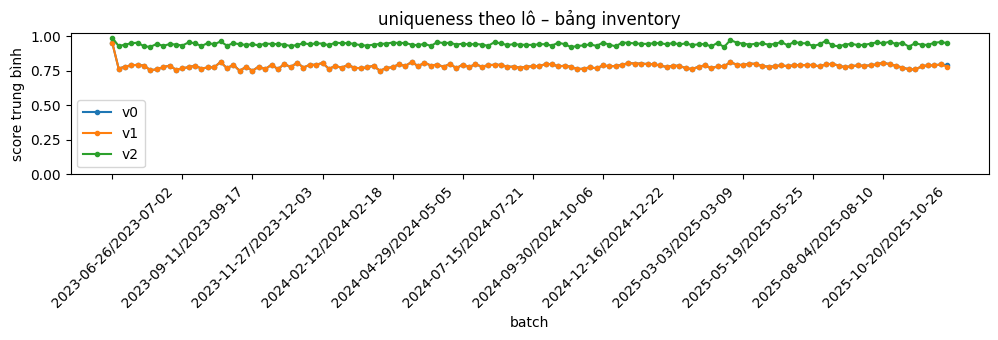

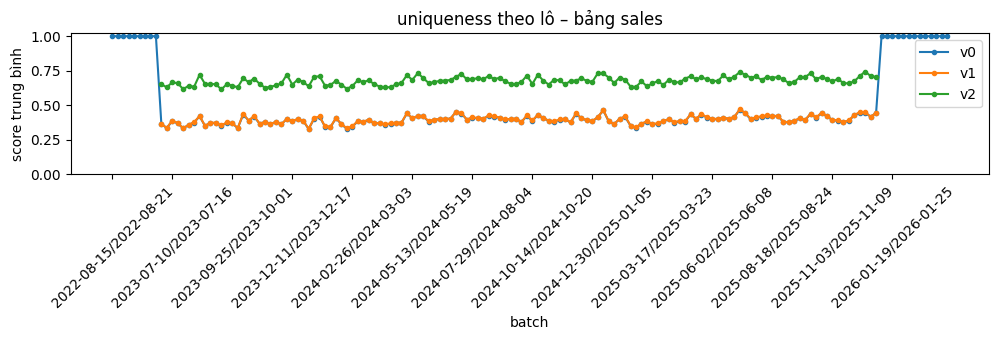

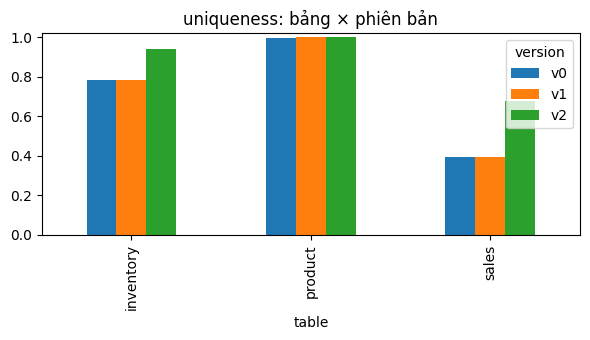

In [8]:
# 8. Tổng hợp theo lô/giai đoạn + biểu đồ  (KHÔNG SỬA)
by_tvb = result.groupby(["table","version","batch"])["score"].mean().reset_index()
by_tvb = by_tvb[~by_tvb["batch"].isin(["NA","NaT"])]

tables_with_time = by_tvb["table"].unique()
if len(tables_with_time) == 0:
    print("Không có bảng nào có trục thời gian -> bỏ qua biểu đồ theo lô.")
for t in tables_with_time:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for v, g in by_tvb[by_tvb.table == t].groupby("version"):
        ax.plot(g["batch"], g["score"], marker="o", ms=3, label=v)
    ax.set_title(f"{DIMENSION} theo lô – bảng {t}"); ax.set_ylim(0, 1.02)
    ax.set_xlabel("batch"); ax.set_ylabel("score trung bình"); ax.legend()
    step = max(1, len(g) // 12); ax.set_xticks(ax.get_xticks()[::step]); plt.xticks(rotation=45)
    plt.tight_layout(); plt.savefig(f"{DIMENSION}_{t}_by_batch.png", dpi=150); plt.show()

# bar so sánh phiên bản theo bảng
piv = by_tv["score_mean"].unstack("version")
piv.plot(kind="bar", figsize=(6, 3.5), ylim=(0, 1.02), title=f"{DIMENSION}: bảng × phiên bản")
plt.tight_layout(); plt.savefig(f"{DIMENSION}_by_table_version.png", dpi=150); plt.show()

## 9. Nhận xét ngắn (3–5 dòng)
- **Bảng/phiên bản điểm thấp nhất:** Bảng `sales` ở phiên bản `v0` có điểm thấp nhất (`score_mean = 0.3936`, tỷ lệ vi phạm 60.64%). Nguyên nhân chủ yếu do hiện tượng gần trùng R3: nhiều khách hàng mua cùng 1 sản phẩm với số lượng 1 chiếc và đơn giá niêm yết trong cùng một ngày (đặc trưng bán lẻ), cộng thêm 1.509 dòng bị trùng lặp hoàn toàn do 845 đơn hàng duplicate trong `SalesOrders.csv`.
- **v1 so với v0:** Bước làm sạch đã triệt tiêu hoàn toàn trùng khóa chính R1 và trùng toàn bộ dòng R2 trên cả `sales` (loại 1.509 dòng) và `product` (loại 1 dòng duplicate `PRD0000213`), đưa điểm `product` từ 0.9965 lên tuyệt đối 1.0000.
- **v2 (Modeling dataset):** Điểm Uniqueness ở `sales` và `inventory` tăng mạnh lên tương ứng 0.6767 và 0.9428 nhờ việc tổng hợp và loại bỏ các giao dịch thưa thớt, đảm bảo tính toàn vẹn cao nhất trước khi đưa vào huấn luyện mô hình.
- **Giai đoạn (batch) bất thường:** Các tuần mùa mua sắm cao điểm cuối năm (tuần 46–48, tháng 11) có lượng giao dịch đột biến dẫn đến tỷ lệ gần trùng R3 tăng cao, làm điểm Uniqueness trung bình của `sales` giảm nhẹ nhưng đây là hiện tượng kinh doanh tự nhiên.

**File nộp:** `uniqueness.parquet`, các ảnh `*.png`, notebook này.